In [2]:
import pandas as pd
import os


Data being used provided by AGSI (Aggregated Gas Storage Inventory) - https://agsi.gie.eu/. The data used is all historical data from European Gas Storage Sites.

In [ ]:
datafile_path = '../../data/AGSI_DATA/'
files = os.listdir(datafile_path)
ng_files = [f for f in files if f.endswith('.json')]

df = pd.DataFrame()

for f in ng_files:
    df_temp = pd.read_json(os.path.join(datafile_path, f))
    country = f.split('_')[1]
    site = f.split('_')[0]
    df_temp['Site'] = site
    df_temp['Country'] = country.split('.')[0]
    df = pd.concat([df, df_temp], ignore_index=True)

In [15]:
df['Country'].value_counts()

Country
Germany           270624
United Kingdom     56380
Romania            45104
France             45104
Netherlands        33828
Austria            28190
CzechRepublic      19552
Italy              16944
Poland             16914
Slovakia           11276
Hungary            11276
Ukraine             5638
Belgium             5638
Bulgaria            5638
Croatia             5638
Denmark             5638
Portugal            5638
Sweden              5638
Latvia              5638
Spain               5638
Name: count, dtype: int64

In [ ]:

df['gasDayStart'] = pd.to_datetime(df['gasDayStart'])
df = df.sort_values(['Site', 'gasDayStart']).reset_index(drop=True)

df['phase'] = 'idle'
df.drop(df[df['status'] == 'N'].index, inplace=True) #dropping rows with no data

df['phase'] = df.apply(lambda row: 'injection' if row['injection'] > row['withdrawal'] else 'withdrawal', axis=1) #changing phase column to be withdrawal or injection

df['phase_change'] = (df.groupby('Site')['phase'].transform(lambda x: x != x.shift()).astype(int)) #helped by claude by Antrhopic, specifically the shift function which compares the current and previous row for changes from injection to withdrawal cycles.
df['cycle_id'] = df.groupby('Site')['phase_change'].cumsum()

cycles = (df.groupby(['Country', 'Site', 'cycle_id', 'phase']) .agg(
            start_date    = ('gasDayStart', 'min'),
            end_date      = ('gasDayStart', 'max'),
            days          = ('cycle_id', 'count')).reset_index()
            )

cycles


,Country,Site,cycle_id,phase,start_date,end_date,days
0,Austria,RAG Energy Storage,1,withdrawal,2011-01-01,2011-02-04,35
1,Austria,RAG Energy Storage,2,injection,2011-02-05,2011-02-06,2
2,Austria,RAG Energy Storage,3,withdrawal,2011-02-07,2011-02-11,5
3,Austria,RAG Energy Storage,4,injection,2011-02-12,2011-02-12,1
4,Austria,RAG Energy Storage,5,withdrawal,2011-02-13,2011-02-23,11
...,...,...,...,...,...,...,...
43872,United Kingdom,UGS Stublach (Post-Brexit),409,withdrawal,2025-01-07,2025-01-23,17
43873,United Kingdom,UGS Stublach (Post-Brexit),410,injection,2025-01-24,2025-01-28,5
43874,United Kingdom,UGS Stublach (Post-Brexit),411,withdrawal,2025-01-29,2025-01-31,3
43875,United Kingdom,UGS Stublach (Post-Brexit),412,injection,2025-02-01,2025-02-10,10


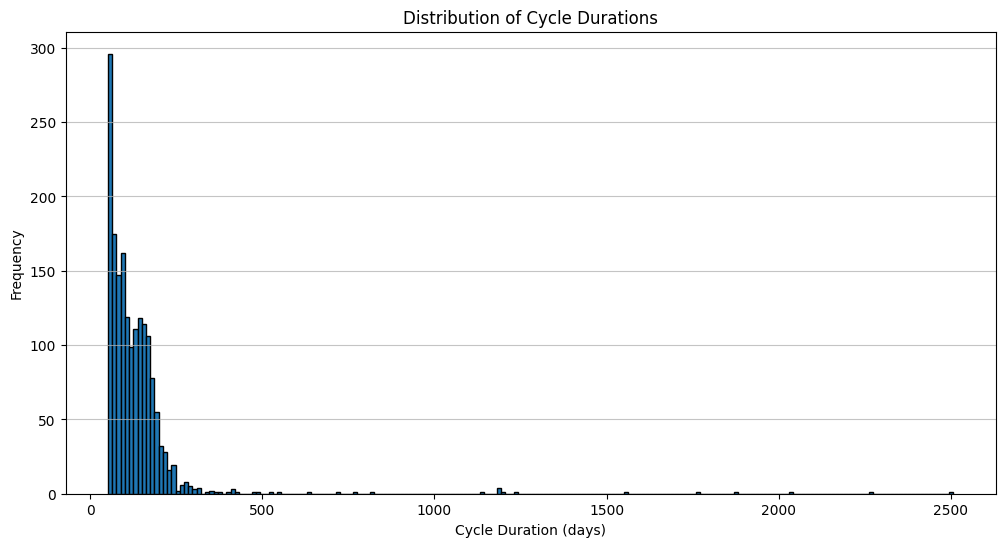

count    1734.000000
mean      132.509804
std       146.601854
min        51.000000
25%        73.000000
50%       110.000000
75%       157.000000
max      2508.000000
Name: days, dtype: float64

In [81]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

plt.hist(cycles[cycles['days'] > 50]['days'], bins=200, edgecolor='black')
plt.title('Distribution of Cycle Durations')
plt.xlabel('Cycle Duration (days)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

cycles[cycles['days'] > 50]['days'].describe()

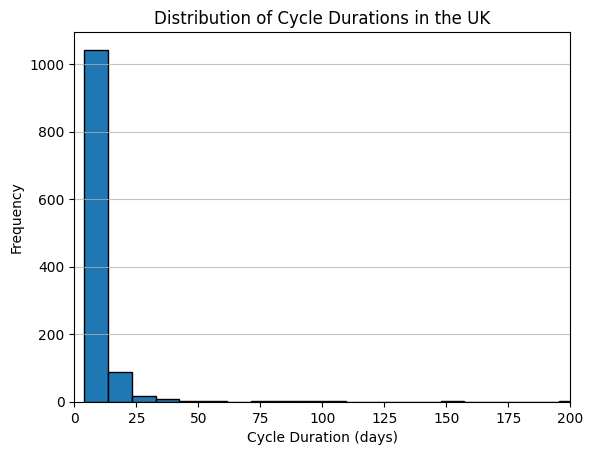

count    1171.000000
mean        8.953886
std        18.803971
min         4.000000
25%         4.000000
50%         5.000000
75%         9.000000
max       483.000000
Name: days, dtype: float64

In [90]:
Uk = cycles[(cycles['Country'] == 'United Kingdom') & (cycles['days'] > 3)]
Uk['days'].describe()

plt.hist(Uk['days'], bins=50, edgecolor='black')
plt.title('Distribution of Cycle Durations in the UK')
plt.xlabel('Cycle Duration (days)')
plt.ylabel('Frequency')
plt.xlim(0, 200)
plt.grid(axis='y', alpha=0.75)
plt.show()
Uk['days'].describe()

In [ ]:
df